In [11]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from interpretability.utils import (
    load_model, load_dataset, load_lut_positions,
    compute_avg_attn, compute_lut_attn_accuracy,
)

In [12]:
SAVED_MODELS = Path("../saved_models")
DATASET_BASE = Path("../datasets")
N_EVAL_SEQS = 512

KS = [1, 2, 3]
STEPS = [500, 1000, 1500, 2000, 2500, 3000, 3500, 4000]  # all checkpoints
HEATMAP_STEPS = [500, 2500, 4000]  # selected for attention heatmaps
MODEL_TEMPLATE = "karity_K{K}_fixed_random_V100_N6000_seed0_model-1l-8h-712e"
DATASET_TEMPLATE = "karity_K{K}_fixed_random_V100_N6000_seed0.npz"

dataset_info = {}
for K in KS:
    npz_path = DATASET_BASE / DATASET_TEMPLATE.format(K=K)
    meta = np.load(npz_path, allow_pickle=True)["metadata"].item()
    lut = np.load(npz_path, allow_pickle=True)["lut_positions"]
    dataset_info[K] = {
        "input_ids": load_dataset(str(npz_path))[:N_EVAL_SEQS],
        "lut_positions": load_lut_positions(str(npz_path)),
        "prefix_len": int(meta["prefix_len"]),
        "cue_positions": [int(lut[k, 0]) for k in range(K)],
    }
    print(f"K={K}: cue positions = {dataset_info[K]['cue_positions']}")

K=1: cue positions = [31]
K=2: cue positions = [31, 19]
K=3: cue positions = [31, 19, 47]


## Compute attention patterns and top-K accuracy

For each K, we use **top-K accuracy** (distributed criterion): take each head's top-K attended
prefix positions, union across all heads. A suffix position is a *hit* if this union covers
all K ground-truth cue positions.

In [13]:
FORCE_RECOMPUTE = False
CACHE_FILE = Path("cache/karity_fixed_random_attn_cache_v4.npz")

cache = {K: {} for K in KS}

if not FORCE_RECOMPUTE and CACHE_FILE.exists():
    cached = np.load(str(CACHE_FILE), allow_pickle=True)
    try:
        for K in KS:
            for step in STEPS:
                cache[K][step] = {
                    "attn_np": cached[f"K{K}_step{step}_attn"],
                    "accuracy": cached[f"K{K}_step{step}_acc"].item(),
                }
        print("Loaded from cache.")
    except KeyError:
        print("Cache miss, recomputing...")
        cache = {K: {} for K in KS}

if not any(cache[K] for K in KS):
    for K in KS:
        info = dataset_info[K]
        for step in STEPS:
            ckpt_path = SAVED_MODELS / MODEL_TEMPLATE.format(K=K) / f"checkpoint-{step}"
            model = load_model(str(ckpt_path))

            avg_attn = compute_avg_attn(model, info["input_ids"])
            attn_np = avg_attn[0].detach().cpu().numpy() if hasattr(avg_attn[0], 'detach') else np.asarray(avg_attn[0])
            acc = compute_lut_attn_accuracy(
                model, info["input_ids"], info["lut_positions"], info["prefix_len"],
                top_ns=[K],
            )
            cache[K][step] = {"attn_np": attn_np, "accuracy": acc}
            print(f"K={K} step={step}: top-{K}={acc[f'overall_accuracy_top{K}']:.3f}")
            del model

    CACHE_FILE.parent.mkdir(parents=True, exist_ok=True)
    save_dict = {}
    for K in KS:
        for step in STEPS:
            save_dict[f"K{K}_step{step}_attn"] = cache[K][step]["attn_np"]
            save_dict[f"K{K}_step{step}_acc"] = np.array(cache[K][step]["accuracy"], dtype=object)
    np.savez_compressed(str(CACHE_FILE), **save_dict)
    print(f"Saved cache to {CACHE_FILE}")

Loaded from cache.


## Attention heatmaps across training steps

One row per K, one column per checkpoint. Red dashed lines mark ground-truth cue positions.

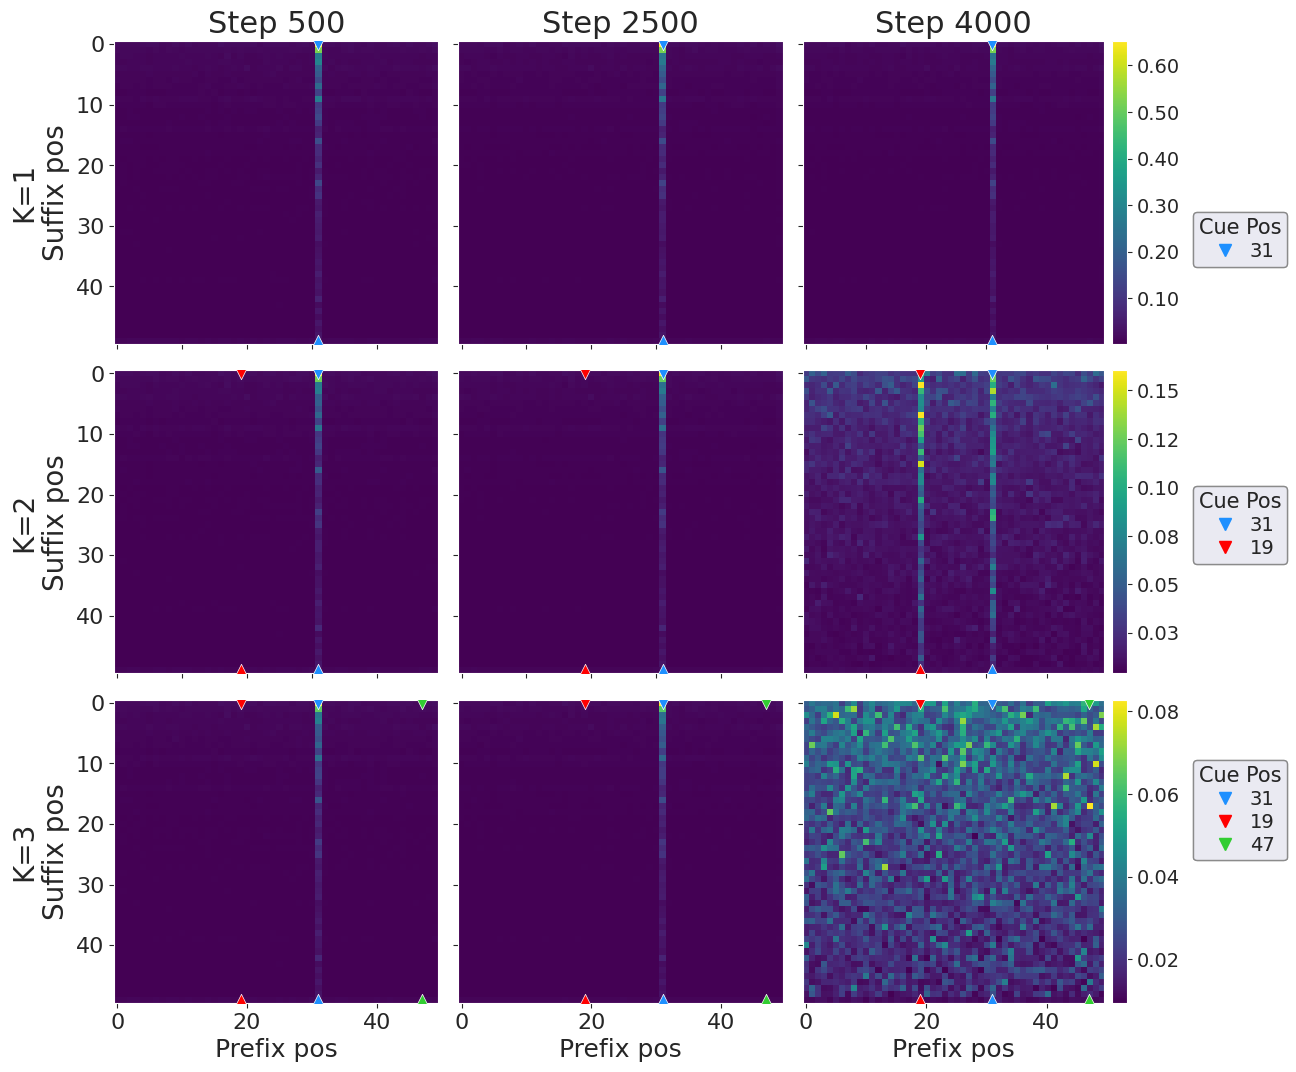

In [32]:
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1 import make_axes_locatable

CUE_COLORS = ["red", "dodgerblue", "limegreen"]  # one per cue index

# Consistent position → color mapping across all K values
all_cue_positions = sorted(set(p for K in KS for p in dataset_info[K]["cue_positions"]))
pos_to_color = {pos: CUE_COLORS[i] for i, pos in enumerate(all_cue_positions)}

fig, axes = plt.subplots(
    len(KS), len(HEATMAP_STEPS),
    figsize=(4 * len(HEATMAP_STEPS), 3.5 * len(KS)),
    squeeze=False,
)

cbar_axes = {}

for row, K in enumerate(KS):
    info = dataset_info[K]
    prefix_len = info["prefix_len"]

    for col, step in enumerate(HEATMAP_STEPS):
        ax = axes[row, col]
        attn_np = cache[K][step]["attn_np"]
        img = attn_np.max(axis=0)[prefix_len:, :prefix_len]

        im = ax.imshow(img, cmap="viridis", aspect="auto")

        # Triangle markers at top and bottom edges for each cue position
        n_suffix = img.shape[0]
        for pos in info["cue_positions"]:
            c = pos_to_color[pos]
            ax.scatter(pos, 0, marker="v", color=c, s=80, zorder=5, edgecolors="white", linewidths=0.5)
            ax.scatter(pos, n_suffix - 1, marker="^", color=c, s=80, zorder=5, edgecolors="white", linewidths=0.5)

        if row == 0:
            ax.set_title(f"Step {step}", fontsize=22)

        # Y-axis: label + tick text only on first column, ticks always visible
        if col == 0:
            ax.set_ylabel(f"K={K}\nSuffix pos", fontsize=20)
            ax.tick_params(axis='y', labelsize=16, left=True, labelleft=True)
        else:
            ax.set_ylabel("")
            ax.tick_params(axis='y', left=True, labelleft=False)

        # X-axis: label + tick text only on last row, ticks always visible
        if row == len(KS) - 1:
            ax.set_xlabel("Prefix pos", fontsize=18)
            ax.tick_params(axis='x', labelsize=16, bottom=True, labelbottom=True)
        else:
            ax.set_xlabel("")
            ax.tick_params(axis='x', bottom=True, labelbottom=False)

        ax.grid(False)

        # Colorbar on the last column
        if col == len(HEATMAP_STEPS) - 1:
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="5%", pad=0.08)
            cbar = fig.colorbar(im, cax=cax, format="%.2f")
            cbar.ax.tick_params(labelsize=14)
            cbar_axes[row] = cax

plt.tight_layout()
fig.subplots_adjust(bottom=0.04)

# Place per-row legend to the right of the colorbar, vertically centered
for row, K in enumerate(KS):
    info = dataset_info[K]
    row_handles = [
        Line2D([0], [0], marker="v", color=pos_to_color[pos], markersize=9,
               linestyle="None", label=f"{pos}")
        for pos in info["cue_positions"]
    ]
    cax = cbar_axes[row]
    cax_bbox = cax.get_position()
    legend = fig.legend(
        handles=row_handles, loc="center left", title="Cue Pos",
        bbox_to_anchor=(cax_bbox.x1 + 0.09, cax_bbox.y0 + cax_bbox.height / 2),
        fontsize=14, title_fontsize=15, framealpha=0.8, edgecolor="gray",
        handletextpad=0.3, borderpad=0.3, labelspacing=0.2,
    )
    fig.add_artist(legend)

plt.savefig("plots/karity_fixed_random_attn_over_training.pdf", dpi=200, bbox_inches="tight")
plt.show()